# Практика по лекции 2: декомпозиция и сглаживание

**Цель:** на одном ряду применить классическую декомпозицию, STL и MSTL и показать, как выбор метода влияет на компоненты и на интерпретацию.

**Данные.** Ряд генерируется функцией `generate_time_series` из лабораторной работы (две сезонности, тренд, шум).
Поверх добавляются **6 выбросов** и **небольшой сдвиг уровня**.

**Что адаптировано под наш ряд.** В лекции пример для почасовых данных с периодами 24 и 168. У нашего генератора шаг 5 минут и две сезонности:

| | Лекция (почасовой ряд) | Наш ряд (шаг 5 минут) |
|---|---|---|
| короткая сезонность | 24 (сутки) | **12** точек (1 час) |
| длинная сезонность | 168 (неделя) | **72** точки (6 часов) |

Длина ряда — 2880 точек (10 суток), то есть 240 коротких и 40 длинных циклов.

**Четыре набора компонент:** классическая декомпозиция, STL, MSTL и **эталон** (истинные компоненты; он известен, потому что ряд синтетический, и нужен для проверки методов).

In [1]:
import os
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import acf

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 0. Данные

### Генератор из лабораторной работы (без изменений)

In [2]:
STEP_MINUTES = 5
PERIOD_1H = 12   # 1 час при шаге 5 минут
PERIOD_6H = 72   # 6 часов при шаге 5 минут

VARIANCE_MODES = ["const", "grow", "decay"]
TREND_MODES = ["none", "fast_up", "slow_up", "fast_down", "slow_down"]
SEASONALITY_MODES = ["none", "one", "two"]

# Суммарное изменение тренда за весь ряд
TREND_TOTAL = {"fast_up": 60.0, "slow_up": 15.0, "fast_down": -60.0, "slow_down": -15.0}


def _unique_path(path):
    if not os.path.exists(path):
        return path
    root, ext = os.path.splitext(path)
    i = 1
    while os.path.exists(f"{root}_{i}{ext}"):
        i += 1
    return f"{root}_{i}{ext}"


def generate_time_series(
    n_points=1000,
    variance="const",
    trend="none",
    seasonality="none",
    base=100.0,
    noise_std=2.0,
    seed=None,
    save_csv=True,
    csv_dir=".",
    save_plot=False,
    plot_path=None,
    show_plot=True,
):
    if n_points < 1:
        raise ValueError("n_points должно быть >= 1")

    rng = np.random.default_rng(seed)

    # Случайный выбор режимов
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    if variance not in VARIANCE_MODES:
        raise ValueError(f"Неизвестный режим дисперсии: {variance}")
    if trend not in TREND_MODES:
        raise ValueError(f"Неизвестный режим тренда: {trend}")
    if seasonality not in SEASONALITY_MODES:
        raise ValueError(f"Неизвестный режим сезонности: {seasonality}")

    # временная ось: с 00:00 текущего дня, шаг 5 минут
    start = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start + timedelta(minutes=STEP_MINUTES * i) for i in range(n_points)]

    idx = np.arange(n_points)
    progress = idx / max(n_points - 1, 1)

    # тренд
    trend_values = np.zeros(n_points) if trend == "none" else TREND_TOTAL[trend] * progress

    # сезонность
    season_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        season_values += 10.0 * np.sin(2 * np.pi * idx / PERIOD_1H)
    if seasonality == "two":
        season_values += 20.0 * np.sin(2 * np.pi * idx / PERIOD_6H)

    # дисперсия:
    if variance == "const":
        sigma = np.full(n_points, noise_std)
    elif variance == "grow":
        sigma = noise_std * (0.25 + 3.75 * progress)
    else:
        sigma = noise_std * (4.0 - 3.75 * progress)

    noise = rng.normal(0.0, 1.0, n_points) * sigma

    values = base + trend_values + season_values + noise
    params = {"n_points": n_points, "variance": variance, "trend": trend,
              "seasonality": seasonality, "seed": seed}

    if save_csv:
        name = "ts_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
        path = _unique_path(os.path.join(csv_dir, name))
        with open(path, "w", encoding="utf-8") as f:
            f.write("timestamp,value\n")
            for t, v in zip(timestamps, values):
                f.write(f"{t:%Y-%m-%d %H:%M:%S},{v:.6f}\n")
        params["csv_file"] = path

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(timestamps, values, lw=0.9)
    ax.set_title(f"variance={variance}, trend={trend}, seasonality={seasonality}, n={n_points}")
    ax.set_xlabel("Время")
    ax.set_ylabel("Значение")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()

    if save_plot:
        if plot_path is None:
            raise ValueError("Укажите plot_path для сохранения графика")
        os.makedirs(os.path.dirname(plot_path) or ".", exist_ok=True)
        fig.savefig(plot_path, dpi=150)
        params["plot_file"] = plot_path

    if show_plot:
        plt.show()
    else:
        plt.close(fig)

    return timestamps, values, params

### Генерация ряда, выбросы и сдвиг уровня

* генератор: рост (`fast_up`, +60 за весь ряд), две сезонности (амплитуды 10 и 20), постоянная дисперсия (σ шума = 2);
* сдвиг уровня: +8 начиная с точки 1800 (примерно 6.25-е сутки);
* выбросы: 6 одиночных скачков величиной 35–60 в случайных точках.

Эталонные компоненты строятся по формулам генератора и используются только для проверки результатов.

In [3]:
N = 2880
P_SHORT, P_LONG = PERIOD_1H, PERIOD_6H   # 12 и 72 точки

ts, vals, params = generate_time_series(
    n_points=N, variance="const", trend="fast_up", seasonality="two",
    seed=11, save_csv=False, show_plot=False,
)
print(params)

i = np.arange(N)
rng = np.random.default_rng(5)

# эталонные компоненты (по формулам генератора)
true_trend = 100.0 + TREND_TOTAL["fast_up"] * i / (N - 1)
true_s_short = 10.0 * np.sin(2 * np.pi * i / P_SHORT)
true_s_long = 20.0 * np.sin(2 * np.pi * i / P_LONG)

# сдвиг уровня и выбросы
SHIFT_AT, SHIFT = 1800, 8.0
level_shift = np.where(i >= SHIFT_AT, SHIFT, 0.0)
out_idx = np.sort(rng.choice(np.arange(150, N - 150), size=6, replace=False))
outliers = np.zeros(N)
outliers[out_idx] = rng.choice([-1, 1], size=6) * rng.uniform(35, 60, size=6)

idx = pd.DatetimeIndex(ts, freq="5min")
y = pd.Series(np.asarray(vals) + level_shift + outliers, index=idx, name="y")

true_trend_full = pd.Series(true_trend + level_shift, index=idx)
true_s_short = pd.Series(true_s_short, index=idx)
true_s_long = pd.Series(true_s_long, index=idx)
true_resid = y - true_trend_full - true_s_short - true_s_long   # шум + выбросы

print("Точек:", len(y), "| шаг:", y.index.freq, "| пропусков:", y.isna().sum())
y.head()

{'n_points': 2880, 'variance': 'const', 'trend': 'fast_up', 'seasonality': 'two', 'seed': 11}
Точек: 2880 | шаг: <5 * Minutes> | пропусков: 0


2026-11-20 00:00:00    100.068386
2026-11-20 00:05:00    109.483451
2026-11-20 00:10:00    114.624341
2026-11-20 00:15:00    114.218288
2026-11-20 00:20:00    114.988080
Freq: 5min, Name: y, dtype: float64

## 1. Визуальный анализ

### 1.1 Весь ряд

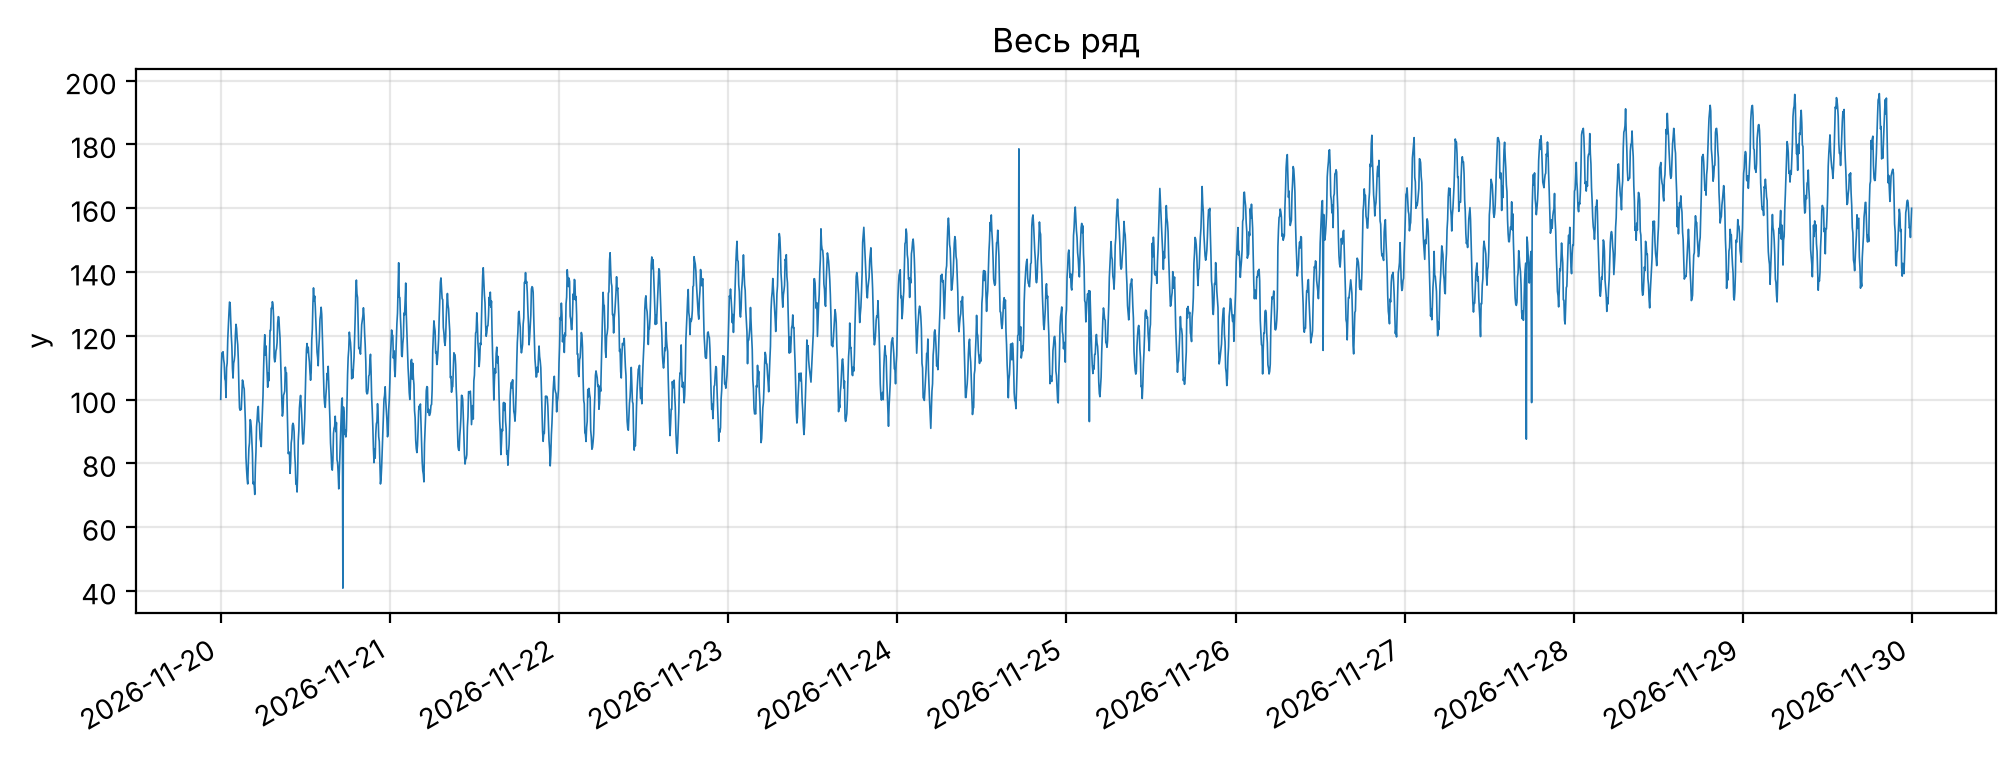

In [4]:
fig, ax = plt.subplots()
ax.plot(y.index, y, lw=0.6)
ax.set_title("Весь ряд"); ax.set_ylabel("y"); fig.autofmt_xdate(); plt.show()

### 1.2 Подсерии: профиль внутри часа и внутри 6-часового цикла

Тренд убираем центрированным скользящим средним с окном 72 (оно гасит обе сезонности), затем усредняем по фазам.

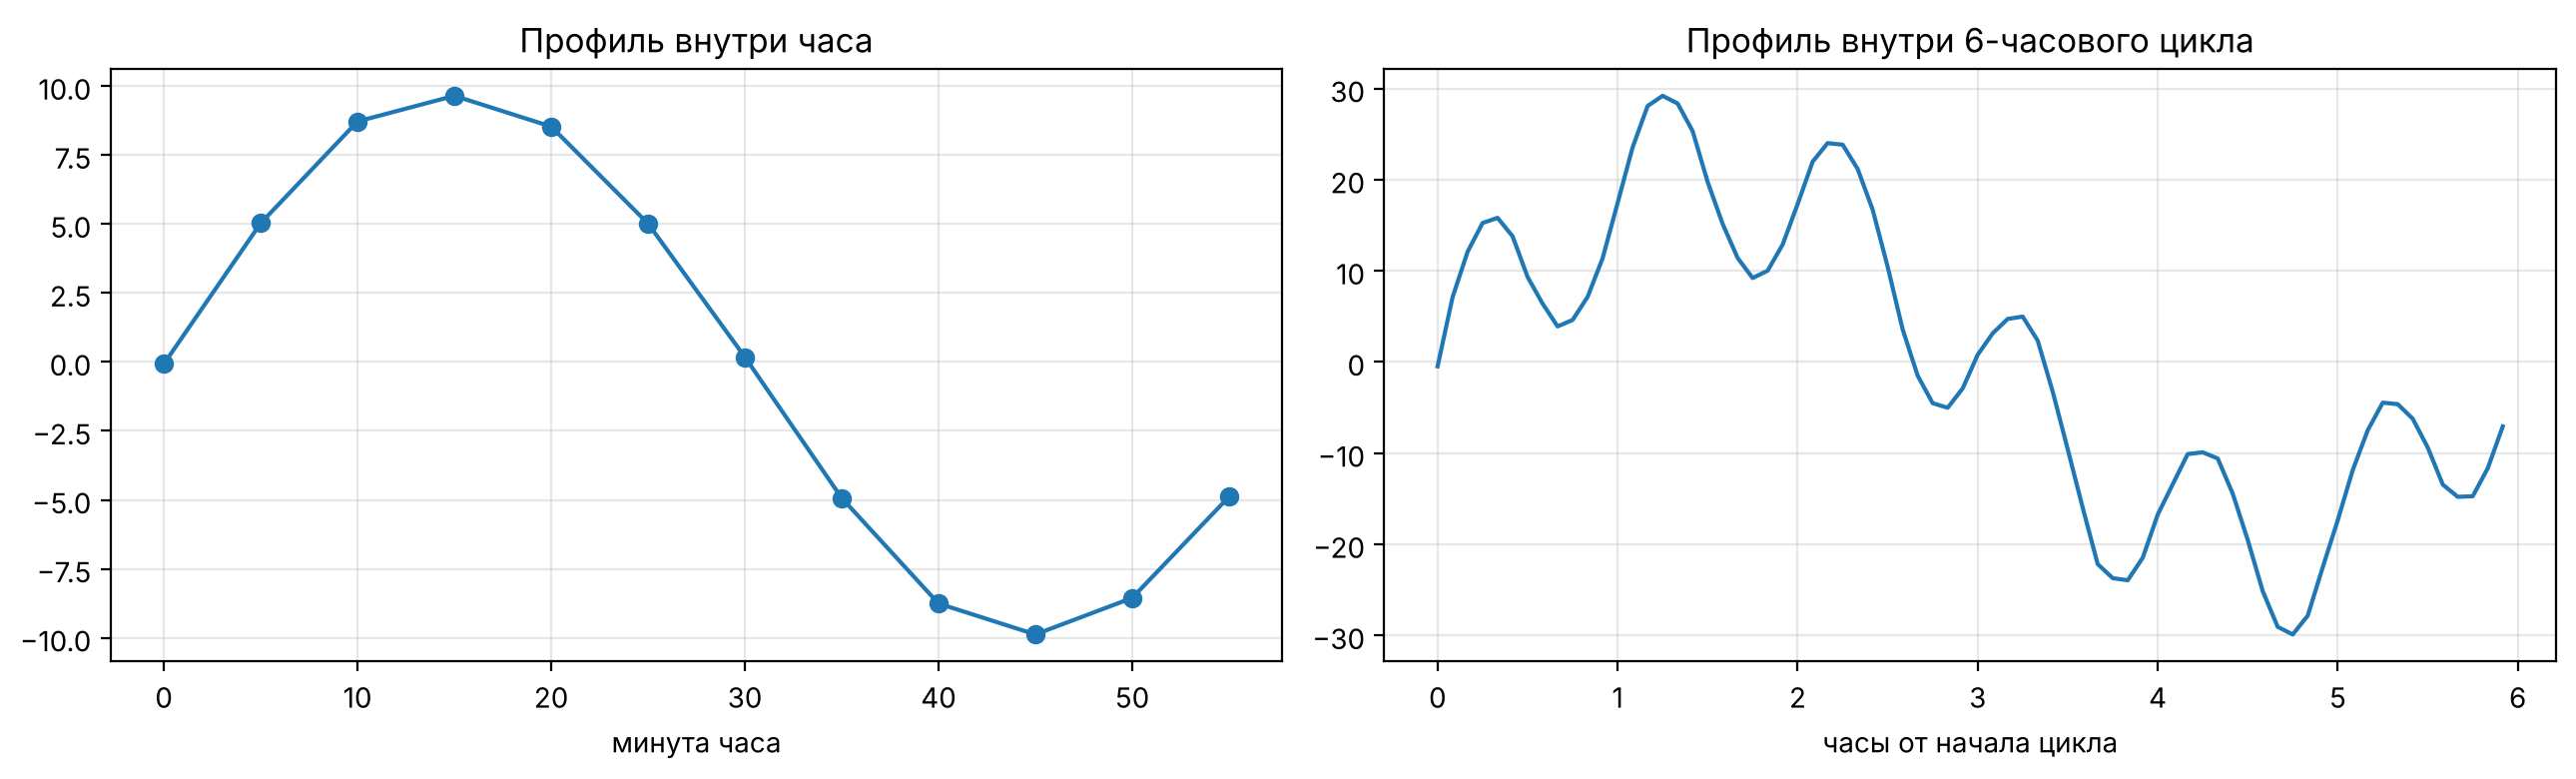

In [5]:
W = P_LONG
trend_ma = y.rolling(W, center=True, min_periods=W // 2).mean()
detr = y - trend_ma

pos12 = i % P_SHORT
pos72 = i % P_LONG

prof12 = detr.groupby(pos12).mean()      # по 6 фазам длинного цикла длинная сезонность сокращается
prof72 = detr.groupby(pos72).median()    # медиана устойчива к выбросам

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(prof12.index * 5, prof12.values, marker="o"); axes[0].set_title("Профиль внутри часа")
axes[0].set_xlabel("минута часа")
axes[1].plot(prof72.index * 5 / 60, prof72.values); axes[1].set_title("Профиль внутри 6-часового цикла")
axes[1].set_xlabel("часы от начала цикла")
plt.tight_layout(); plt.show()

### 1.3 Heatmap «фаза часа × час 6-часового цикла»

Аналог «час × день недели» из лекции: по строкам положение внутри короткой сезонности, по столбцам — внутри длинной.

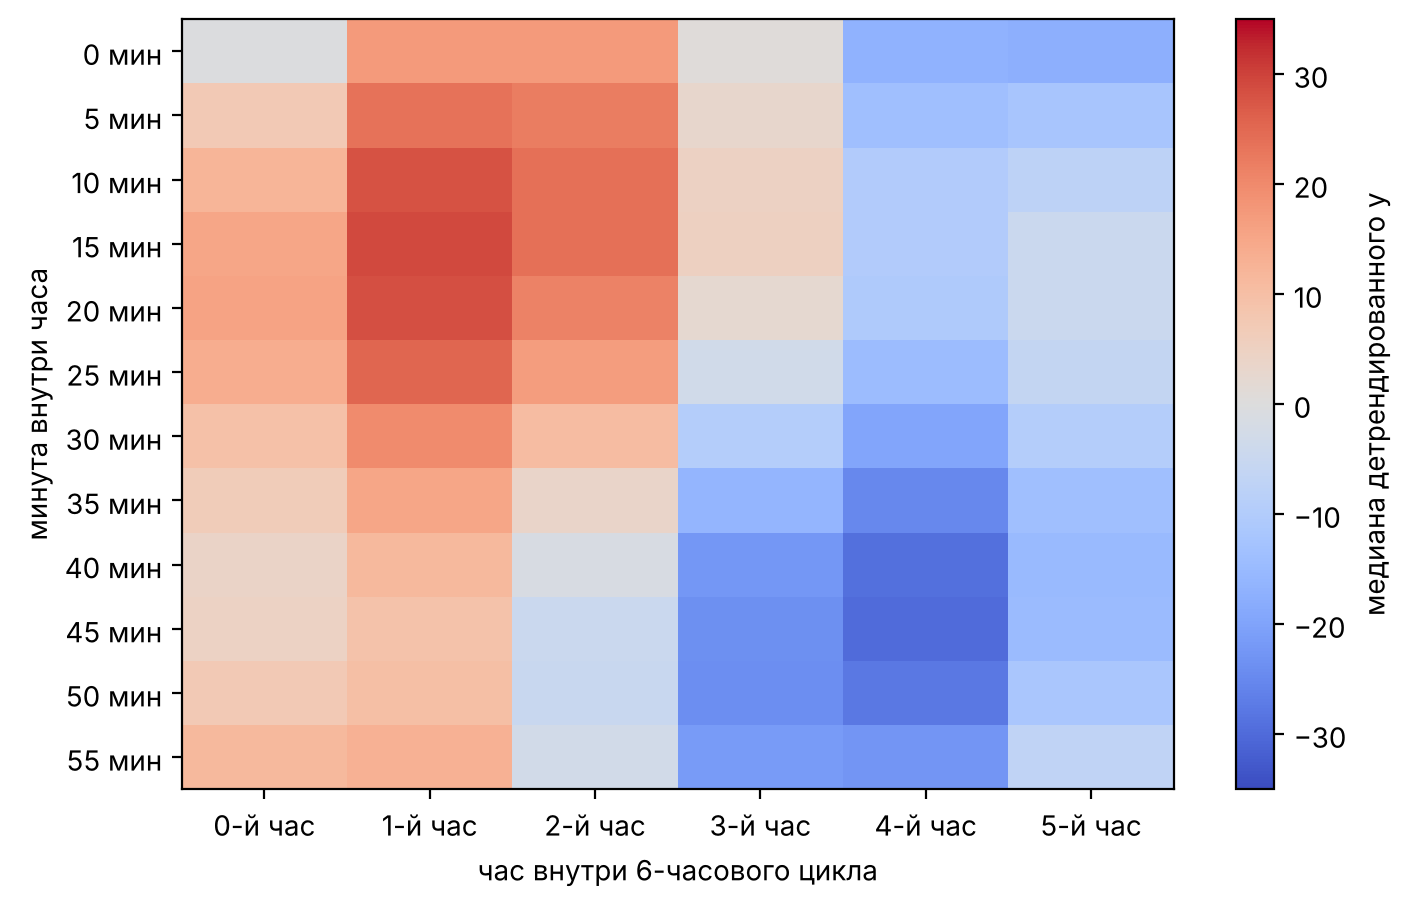

In [6]:
hm = detr.groupby([pos12, pos72 // P_SHORT]).median().unstack()
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(hm.to_numpy(), aspect="auto", cmap="coolwarm", vmin=-35, vmax=35)
ax.set_xticks(range(6)); ax.set_xticklabels([f"{h}-й час" for h in range(6)])
ax.set_yticks(range(12)); ax.set_yticklabels([f"{m} мин" for m in range(0, 60, 5)])
ax.set_xlabel("час внутри 6-часового цикла"); ax.set_ylabel("минута внутри часа"); ax.grid(False)
fig.colorbar(im, ax=ax, label="медиана детрендированного y"); plt.show()

### 1.4 Аддитивная или мультипликативная модель?

Смотрим, как размах сезонности зависит от уровня ряда. Для каждого 6-часового цикла считаем размах детрендированного ряда и средний уровень.
Если размах растёт вместе с уровнем — мультипликативная модель, если не зависит — аддитивная.

Уровень ряда: от 102 до 166
Размах сезонности (5–95%): в первых 5 циклах 51.0, в последних 5 циклах 50.6
Корреляция размаха с уровнем: 0.12


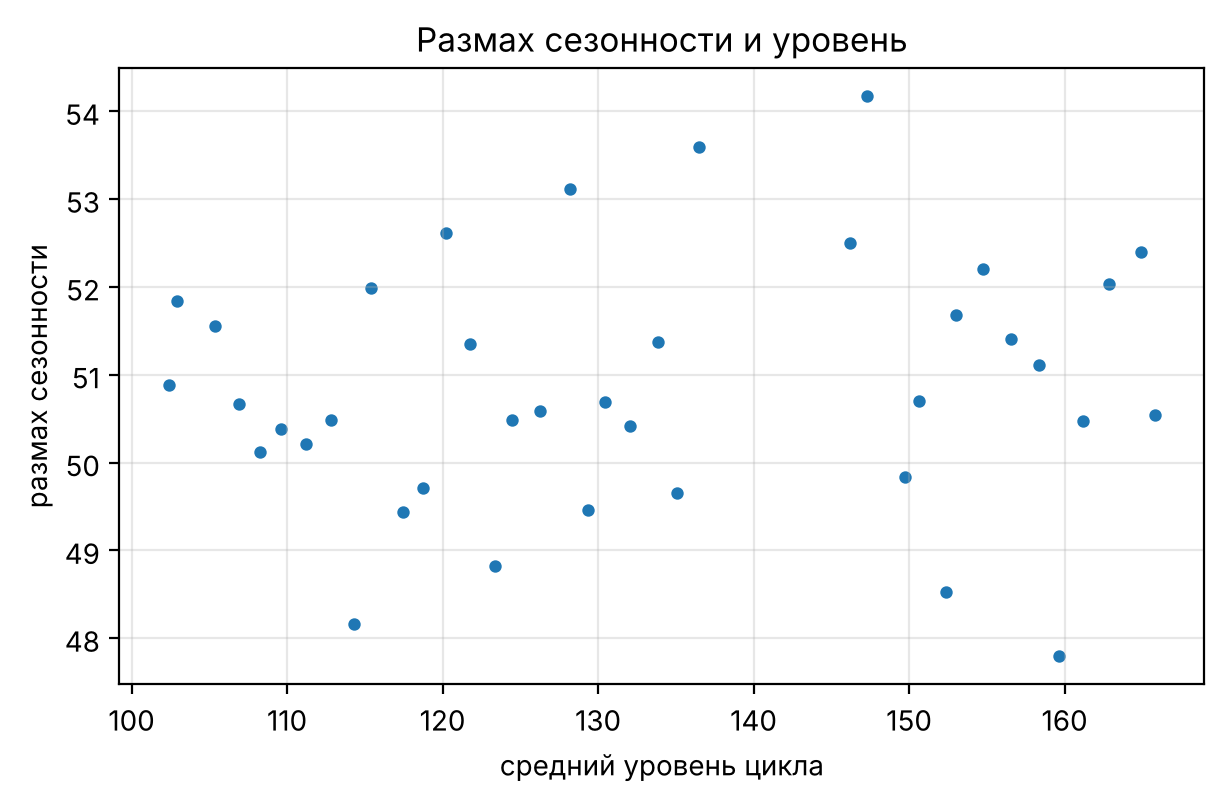

In [7]:
cycle = i // P_LONG
rng_by_cycle = detr.groupby(cycle).agg(lambda s: s.quantile(0.95) - s.quantile(0.05))
level_by_cycle = y.groupby(cycle).mean()

# первые/последние циклы отбрасываем из-за краёв скользящего среднего
r = rng_by_cycle.iloc[1:-1]; l = level_by_cycle.iloc[1:-1]
print("Уровень ряда: от %.0f до %.0f" % (l.iloc[0], l.iloc[-1]))
print("Размах сезонности (5–95%%): в первых 5 циклах %.1f, в последних 5 циклах %.1f" % (r.iloc[:5].mean(), r.iloc[-5:].mean()))
print("Корреляция размаха с уровнем: %.2f" % np.corrcoef(r, l)[0, 1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(l, r, s=12); ax.set_xlabel("средний уровень цикла"); ax.set_ylabel("размах сезонности")
ax.set_title("Размах сезонности и уровень"); plt.show()

**Вывод по модели:** уровень растёт, но размах сезонности остаётся примерно постоянным, значит модель **аддитивная** (рост сам по себе не делает модель мультипликативной).

## 2. ACF

Проверяем, что на лагах 12 и 72 есть пики: это подтверждает две сезонности. ACF считается по детрендированному ряду (из ряда вычтено скользящее среднее), иначе тренд забивает остальные эффекты.

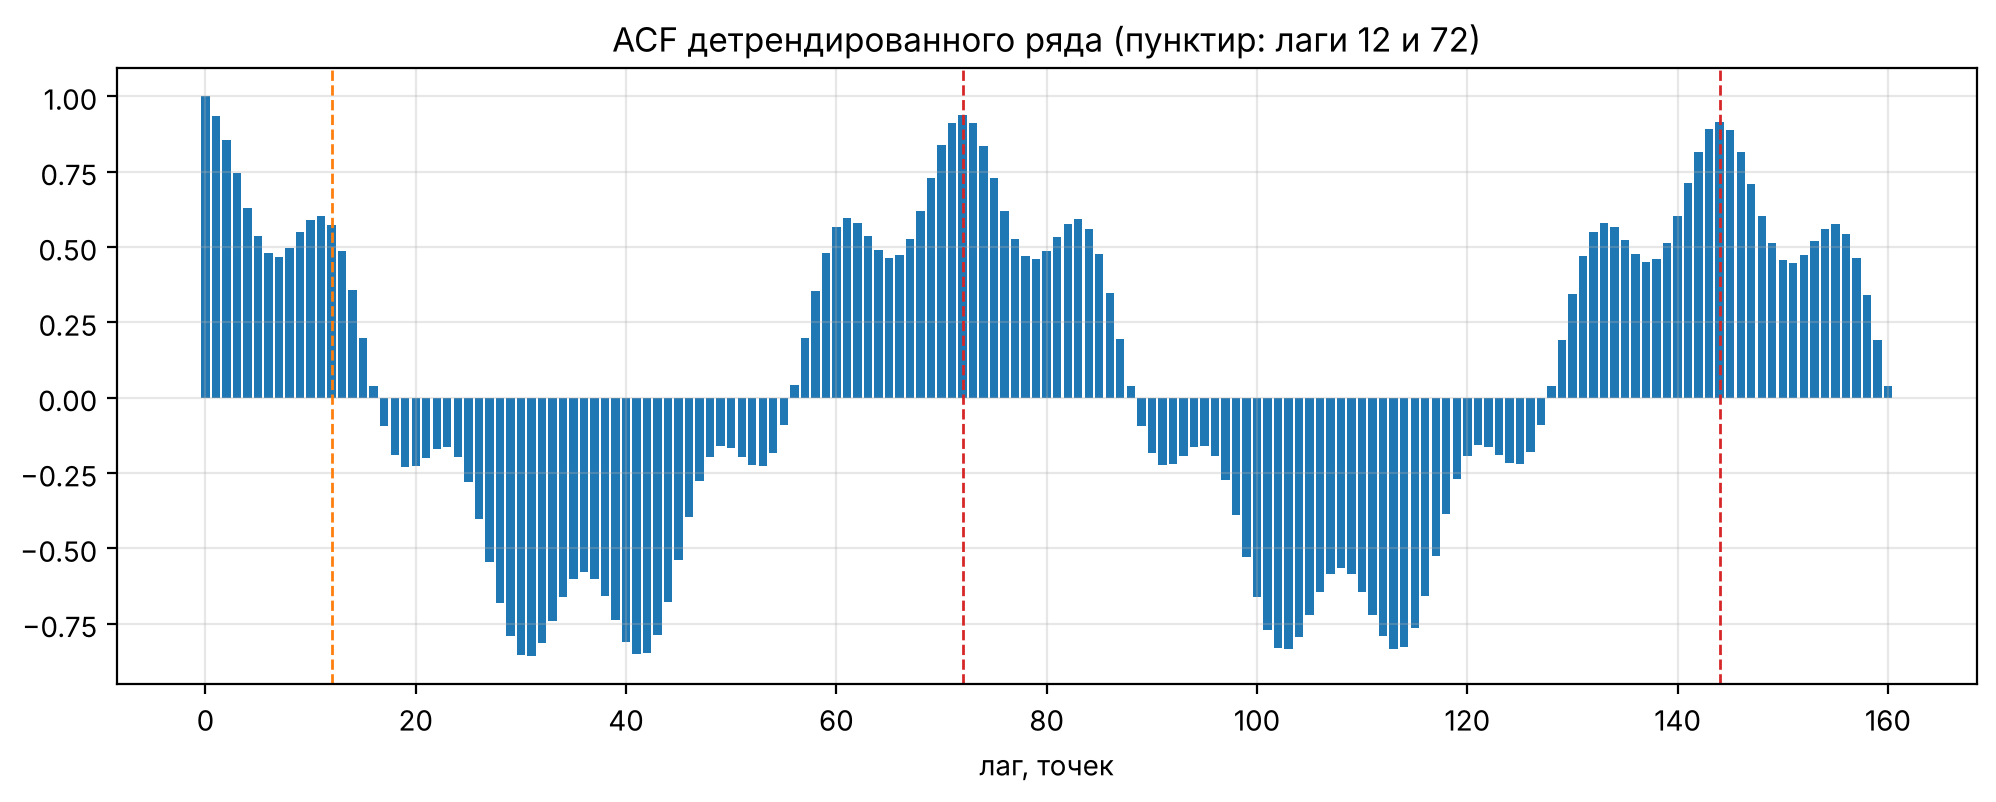

ACF на лаге 12: 0.57, на лаге 72: 0.94, на лаге 6: 0.48, на лаге 36: -0.58


In [8]:
NLAGS = 160
a = acf(detr.dropna(), nlags=NLAGS, fft=True)

fig, ax = plt.subplots()
ax.bar(range(NLAGS + 1), a, width=0.8)
for lag, c in [(P_SHORT, "C1"), (P_LONG, "C3"), (2 * P_LONG, "C3")]:
    if lag <= NLAGS:
        ax.axvline(lag, color=c, ls="--", lw=1)
ax.set_title("ACF детрендированного ряда (пунктир: лаги 12 и 72)")
ax.set_xlabel("лаг, точек"); plt.show()
print("ACF на лаге 12: %.2f, на лаге 72: %.2f, на лаге 6: %.2f, на лаге 36: %.2f" % (a[12], a[72], a[6], a[36]))

## 3. Классическая декомпозиция с `period=12`

Модель аддитивная. Задан только короткий период, поэтому 6-часовой цикл в сезонную компоненту не попадает. Смотрим, куда он денется.

Потеряно точек по краям (NaN в тренде/остатке): 12 из 2880


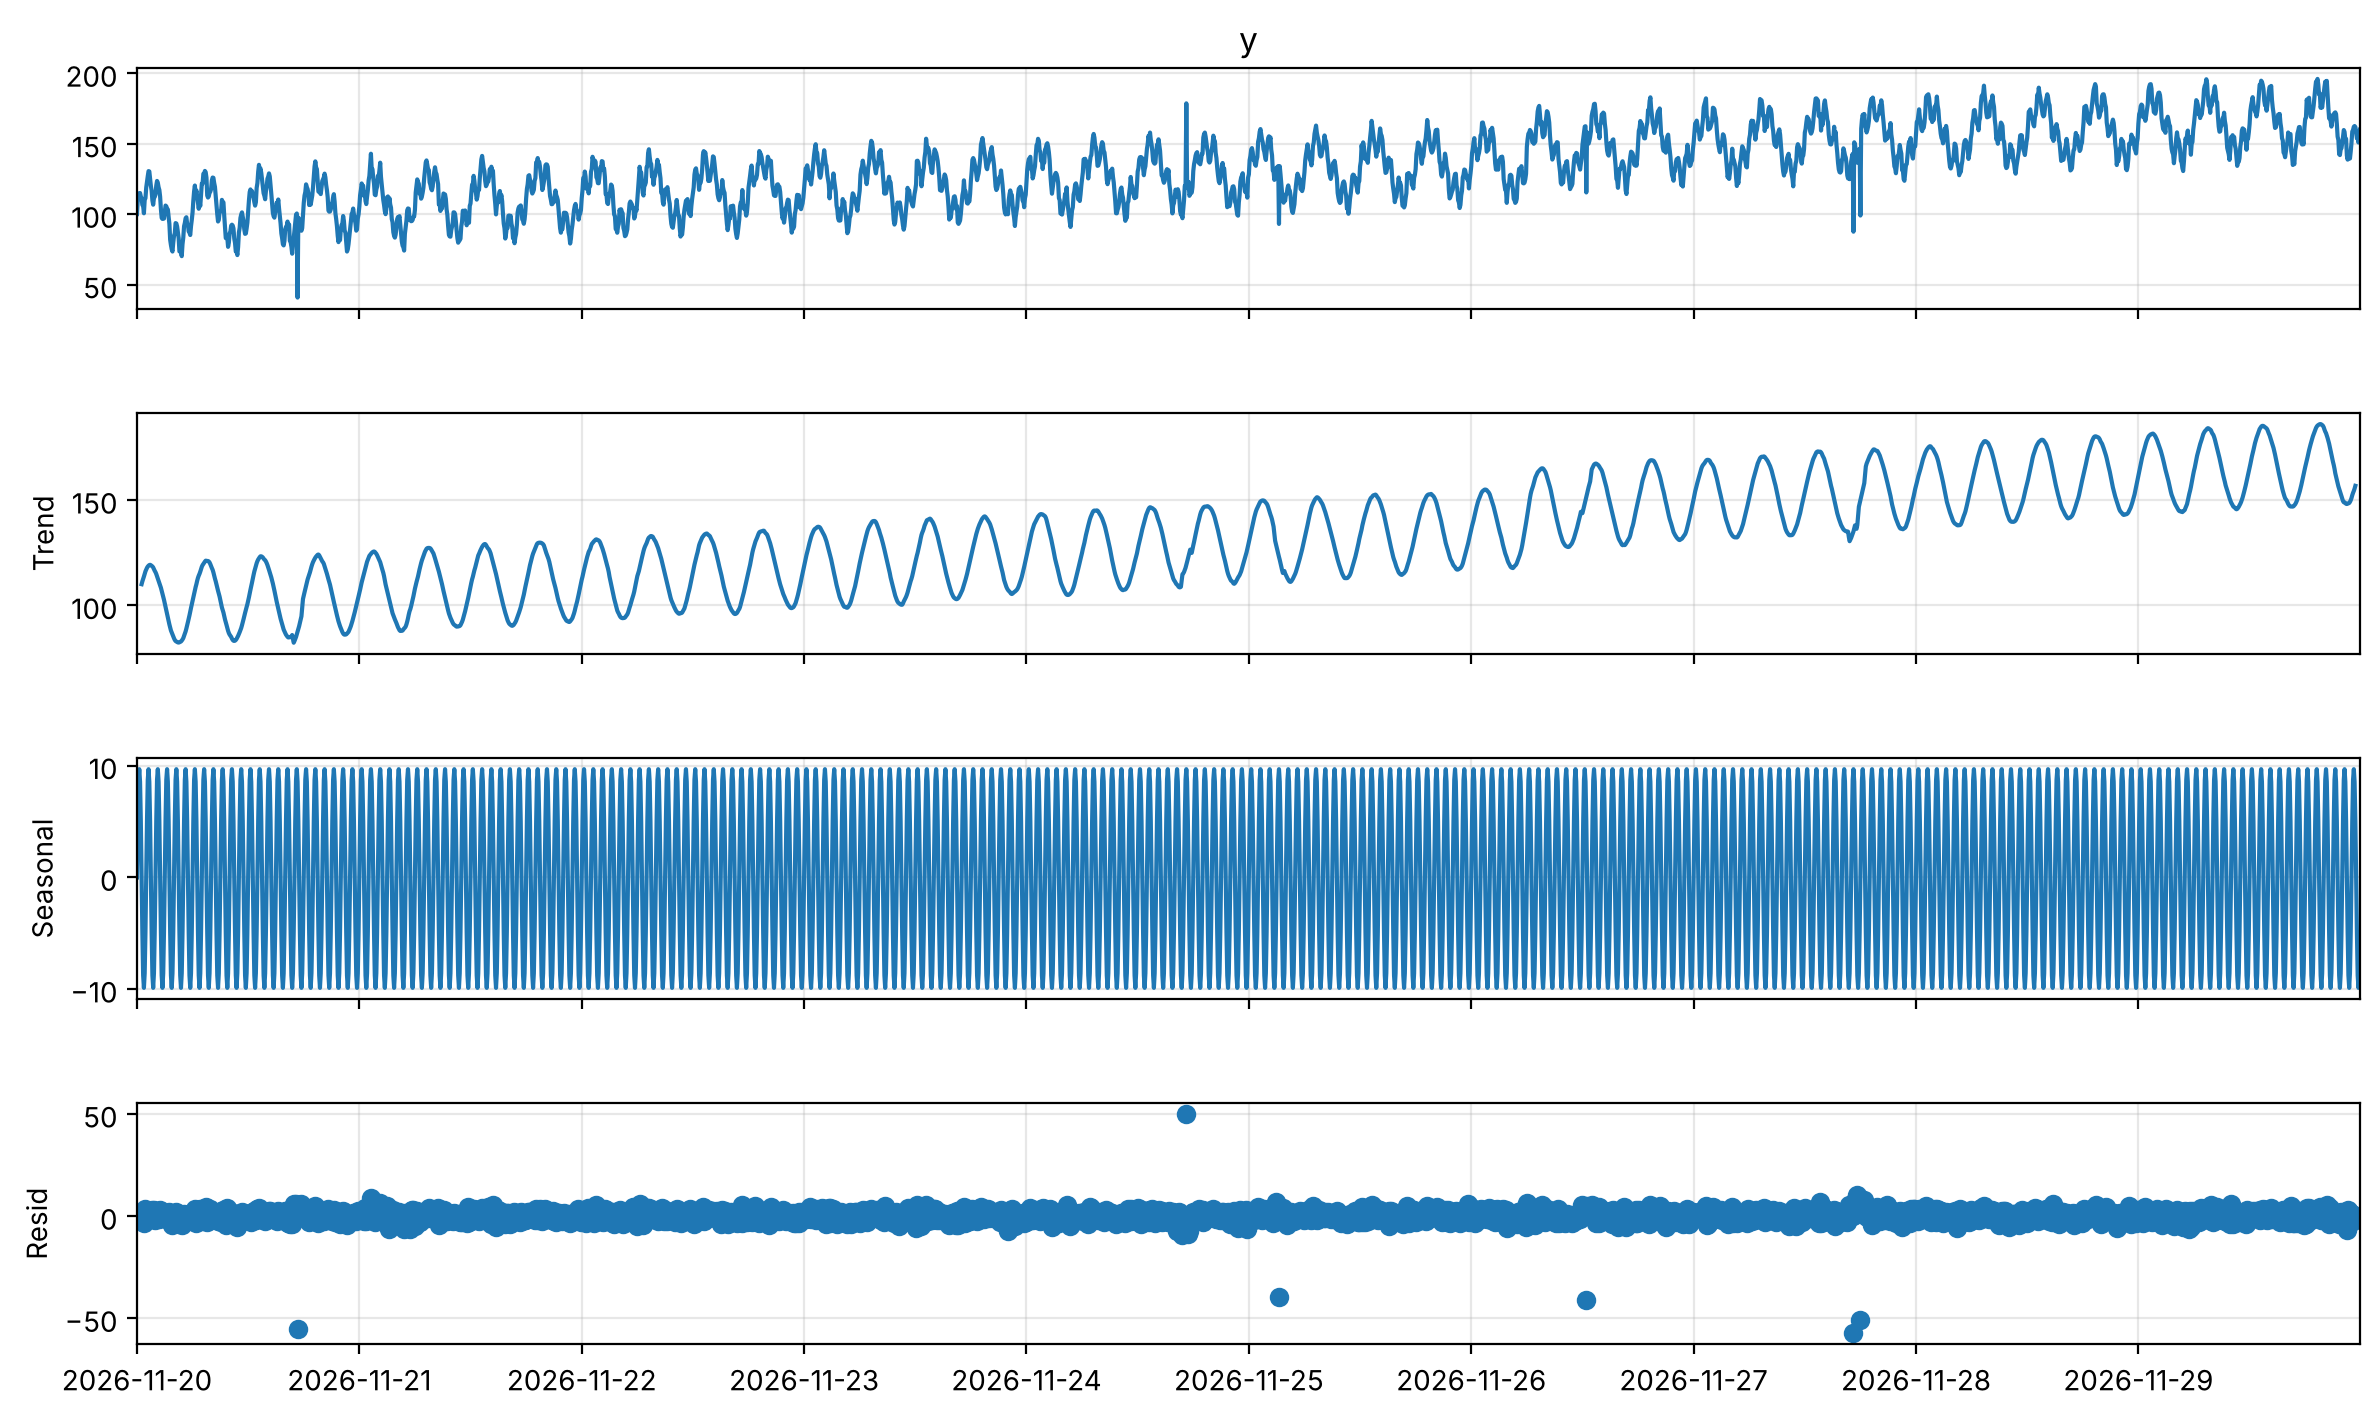

In [9]:
cl = seasonal_decompose(y, model="additive", period=P_SHORT)
print("Потеряно точек по краям (NaN в тренде/остатке):", int(cl.resid.isna().sum()), "из", N)
fig = cl.plot(); fig.set_size_inches(12, 8); plt.show()

## 4. STL с `period=12`, `robust=True`

Параметры `season` и `trend` оставлены по умолчанию (в statsmodels `season=7`, окно тренда вычисляется из периода). Эта настройка и определяет, куда попадёт длинная сезонность.

Окно тренда по умолчанию (формула statsmodels): 23 точек, то есть меньше периода 72


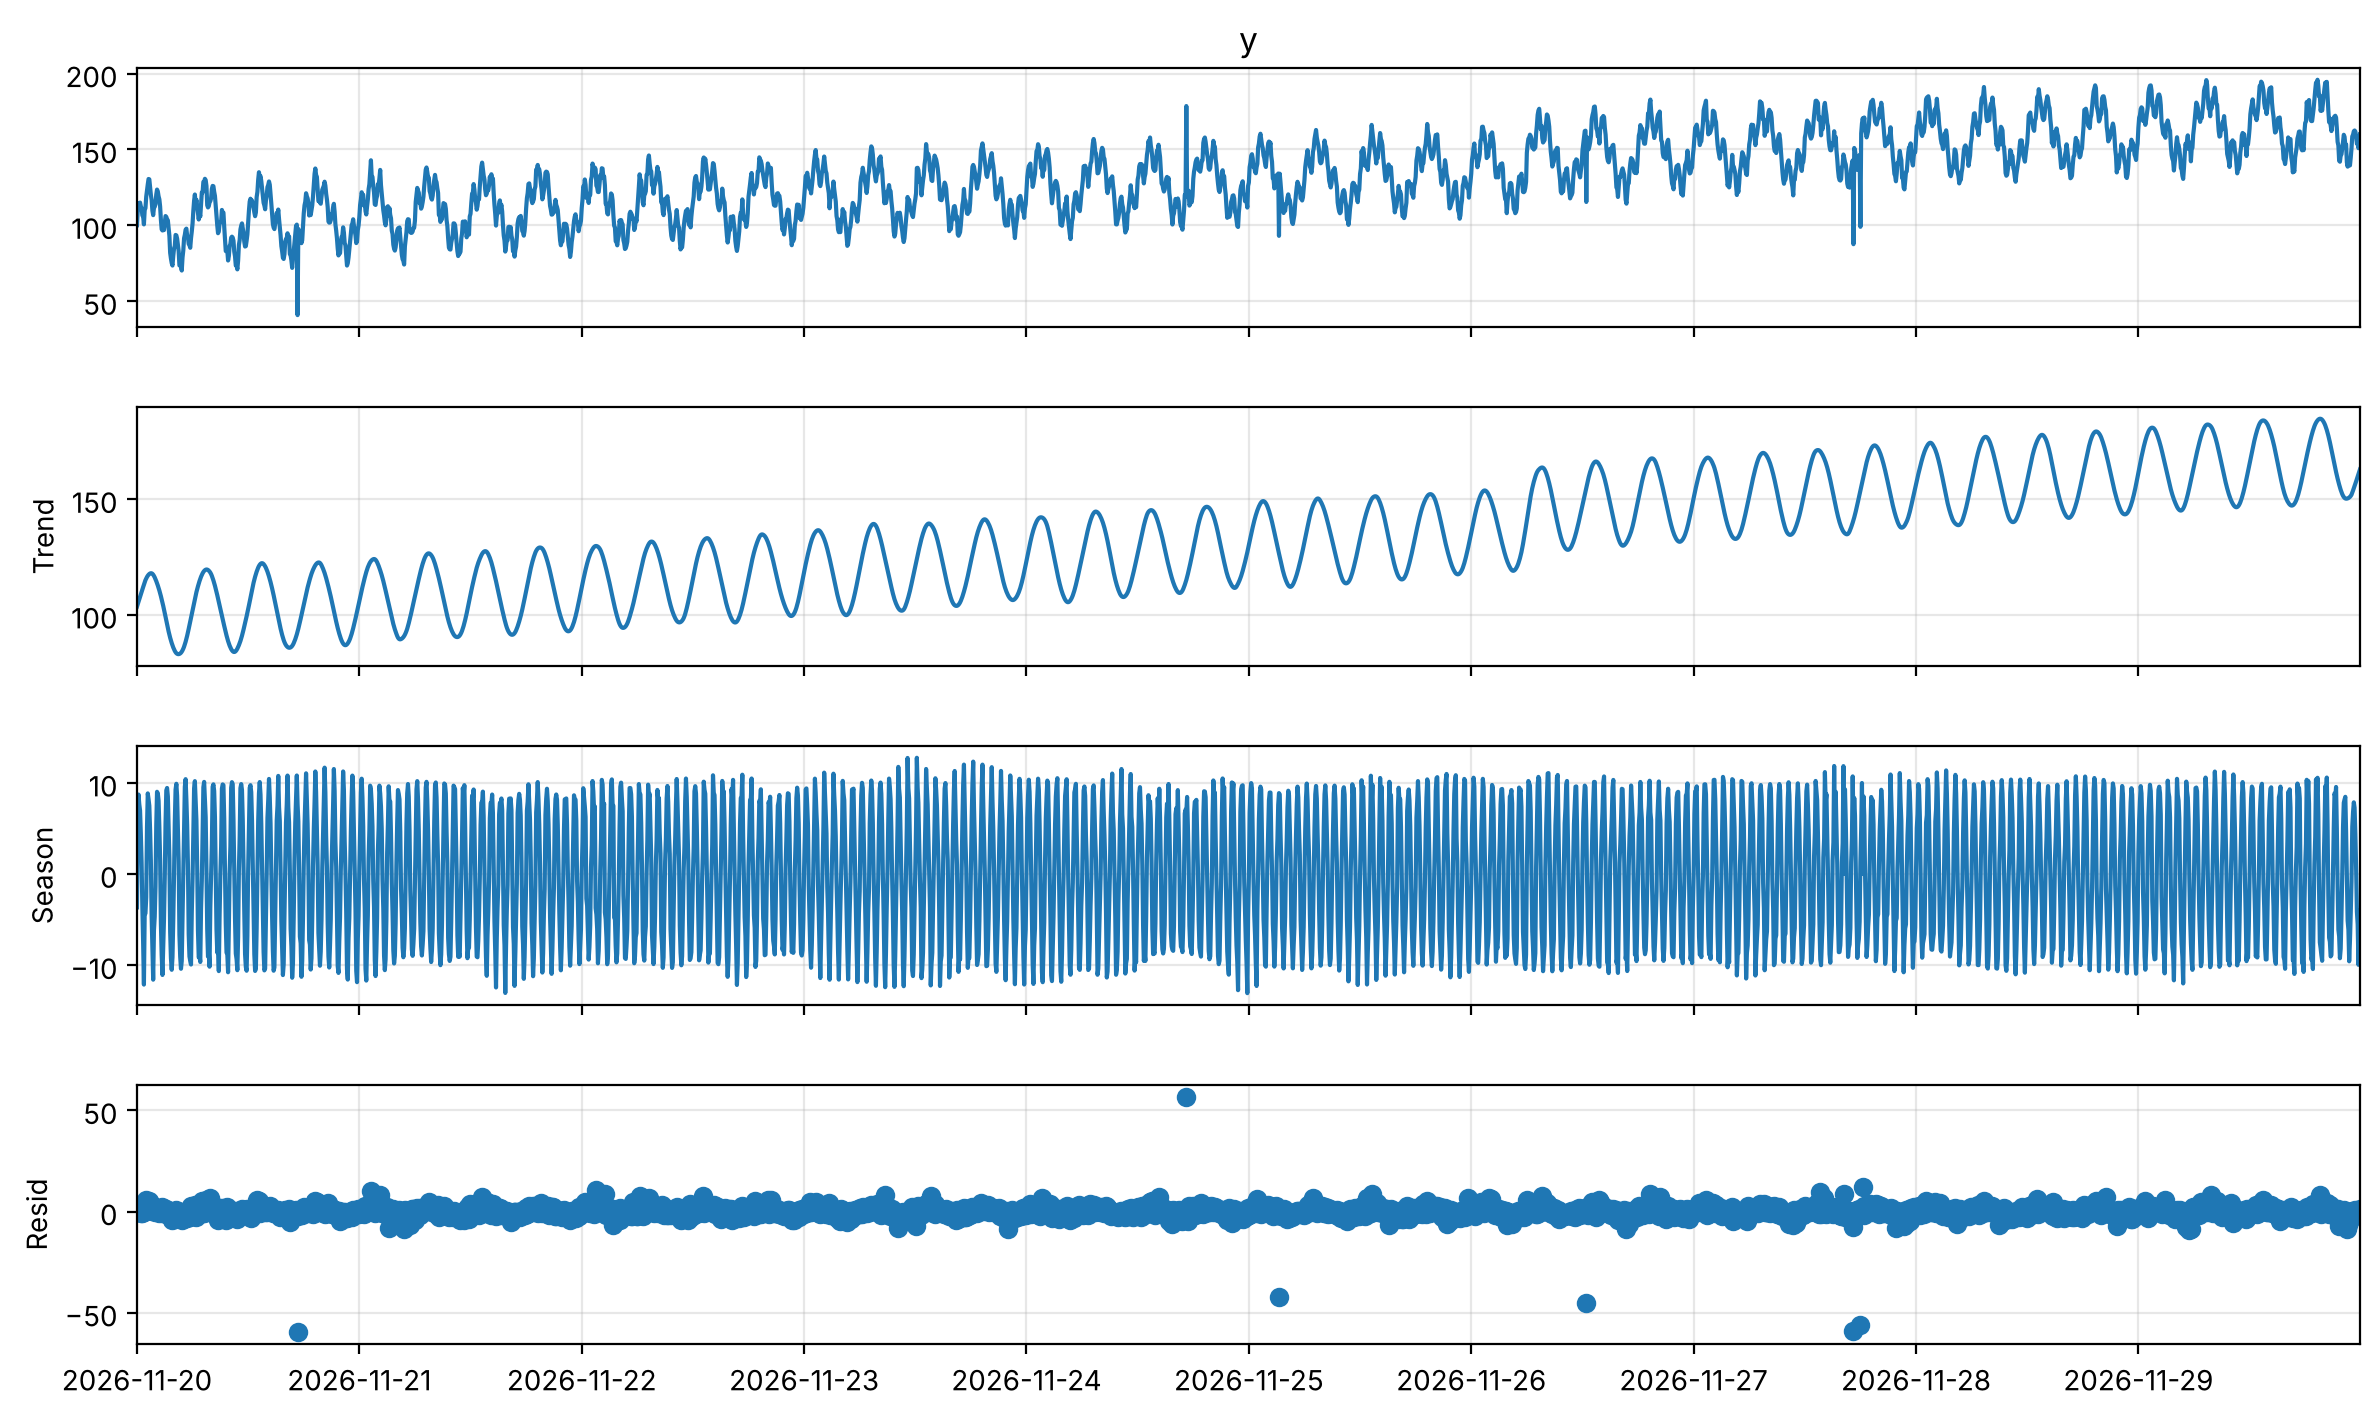

In [10]:
stl = STL(y, period=P_SHORT, robust=True).fit()
t_win = int(np.ceil(1.5 * P_SHORT / (1 - 1.5 / 7)))
t_win += (t_win % 2 == 0)
print("Окно тренда по умолчанию (формула statsmodels):", t_win, "точек, то есть меньше периода 72")
fig = stl.plot(); fig.set_size_inches(12, 8); plt.show()

## 5. MSTL с `periods=(12, 72)`, `robust=True`

Обе сезонности извлекаются отдельно. Периоды кратны (72 = 6 × 12), поэтому, как предупреждает лекция, сезонности возможно идентифицируются частично, и интерпретировать их нужно аккуратно.

Сезонные компоненты: ['seasonal_12', 'seasonal_72']


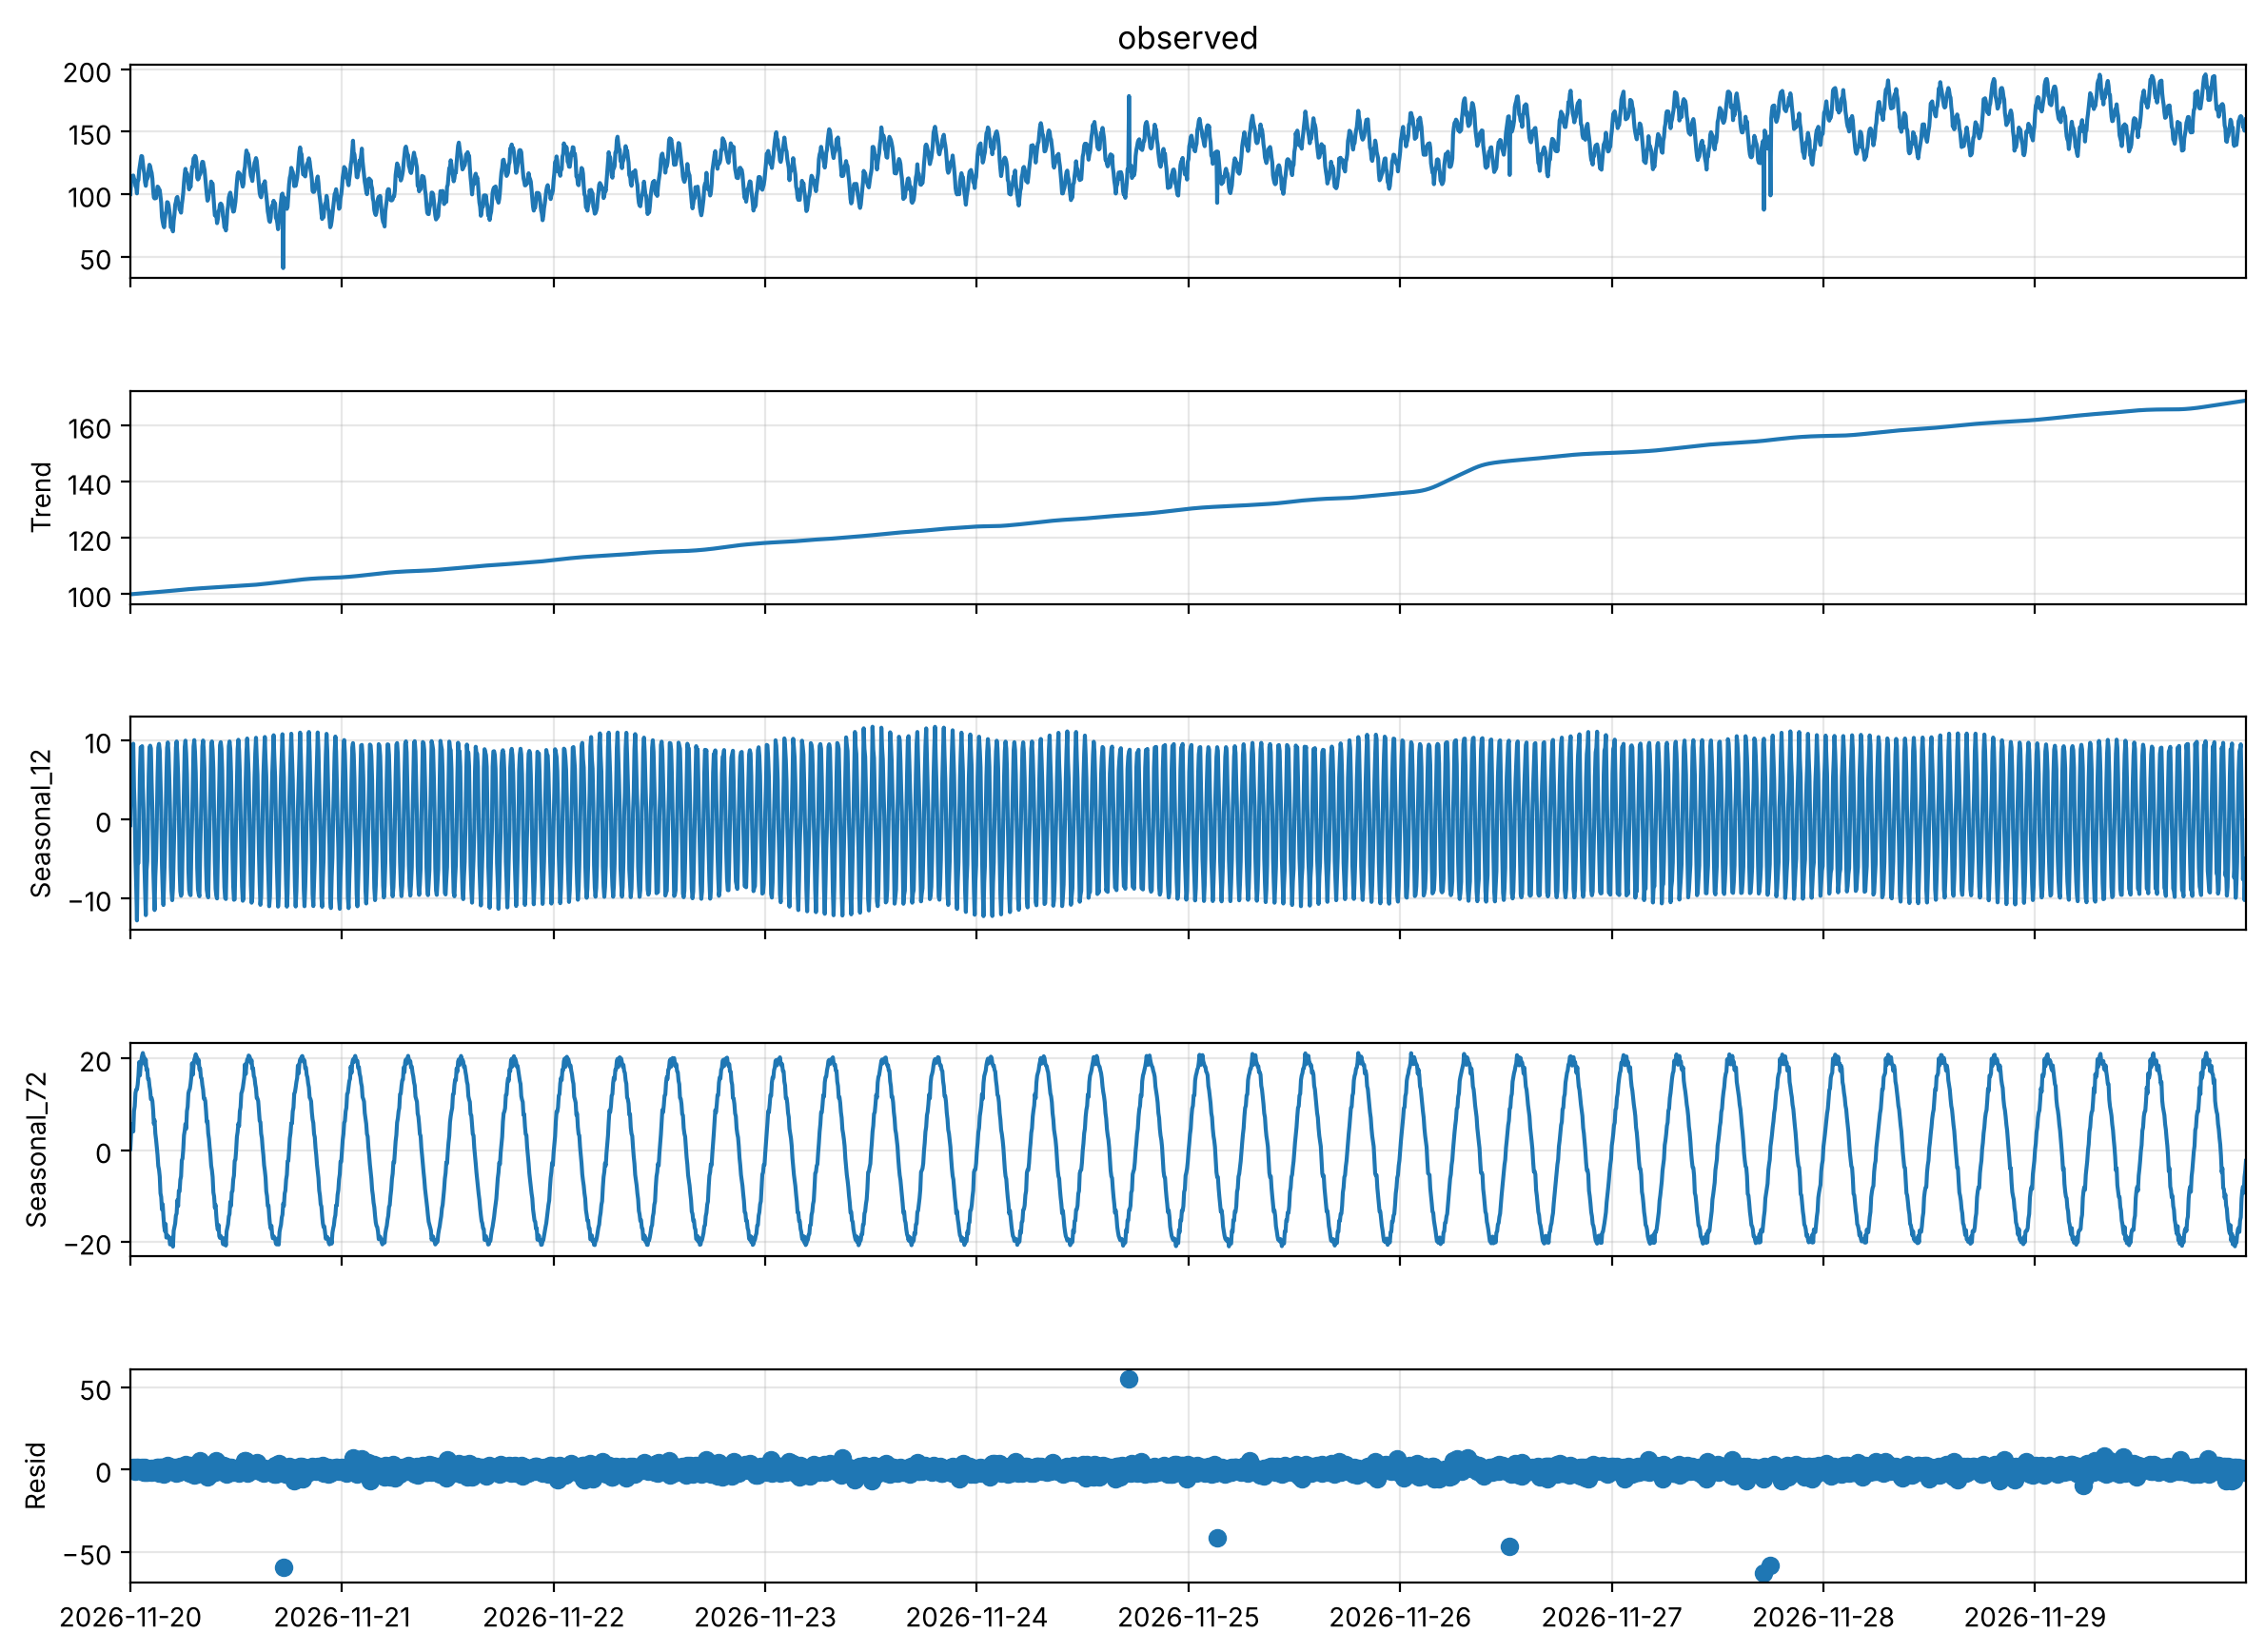

In [11]:
mstl = MSTL(y, periods=(P_SHORT, P_LONG), stl_kwargs={"robust": True}).fit()
print("Сезонные компоненты:", list(mstl.seasonal.columns))
fig = mstl.plot(); fig.set_size_inches(12, 10); plt.show()

## 6. Количественное сравнение

### 6.1 Остатки: график и ACF

Сравнение ведём на общем наборе точек (без краёв, которые теряет классический метод).

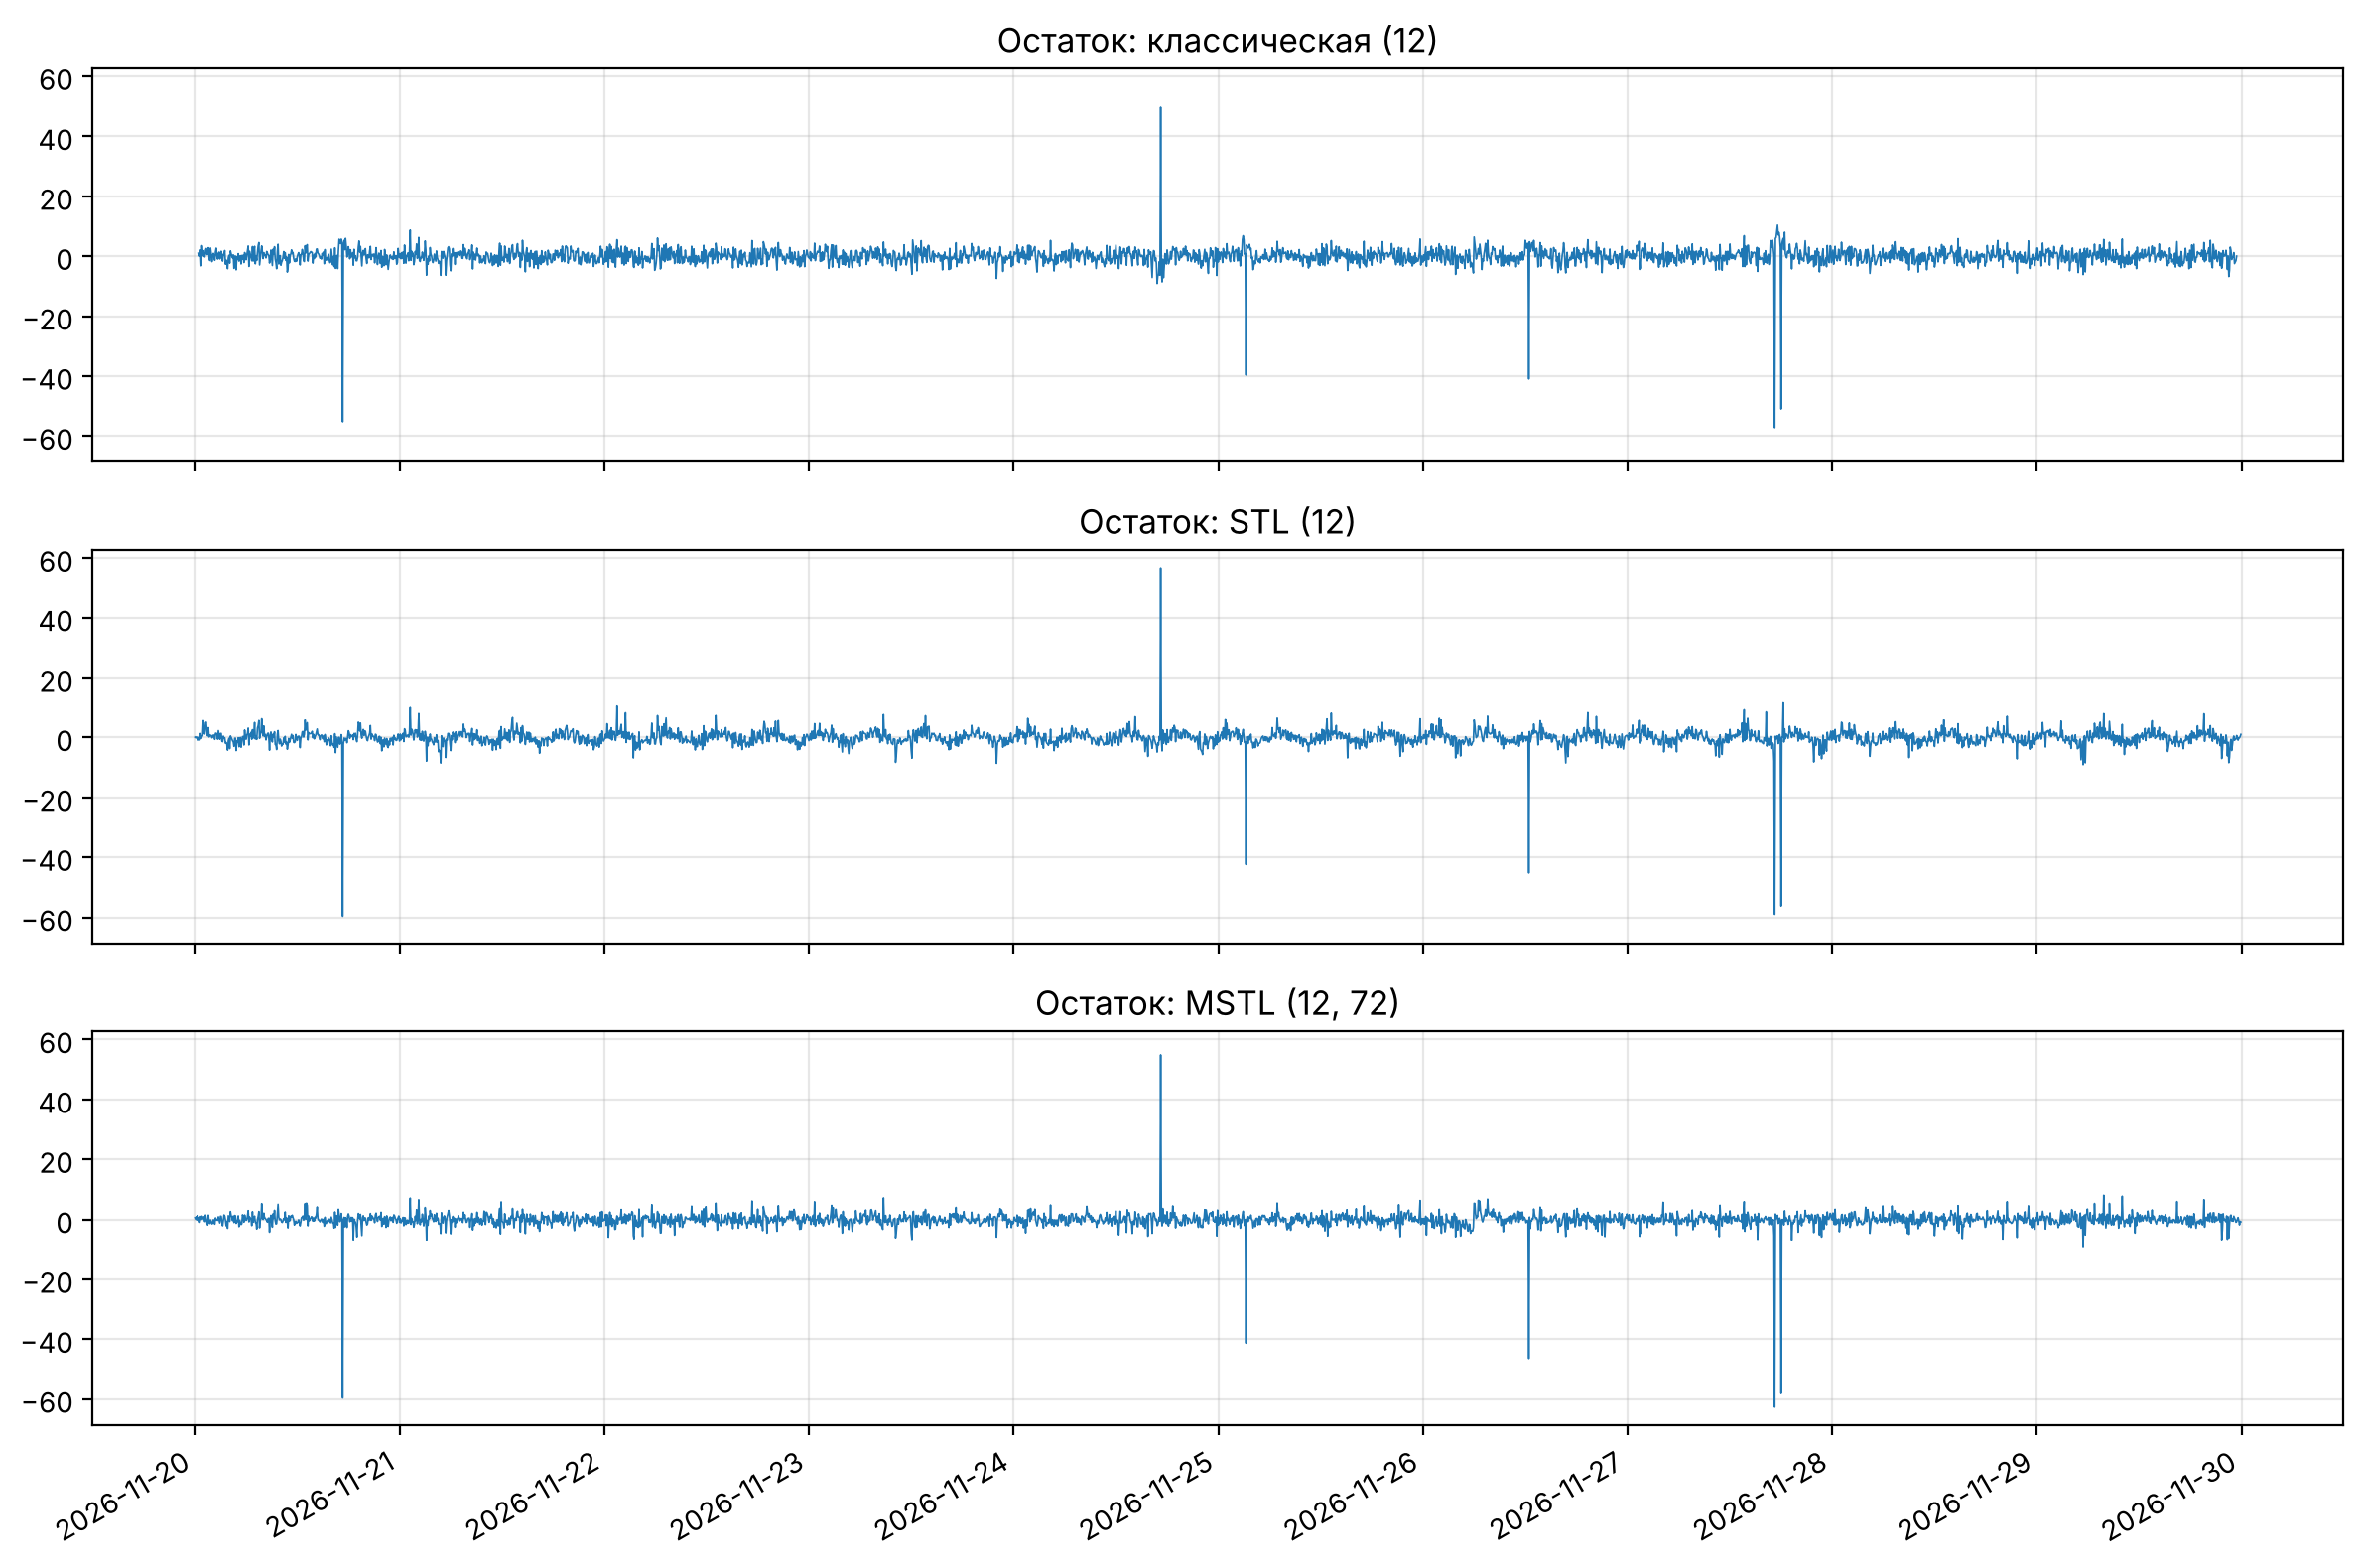

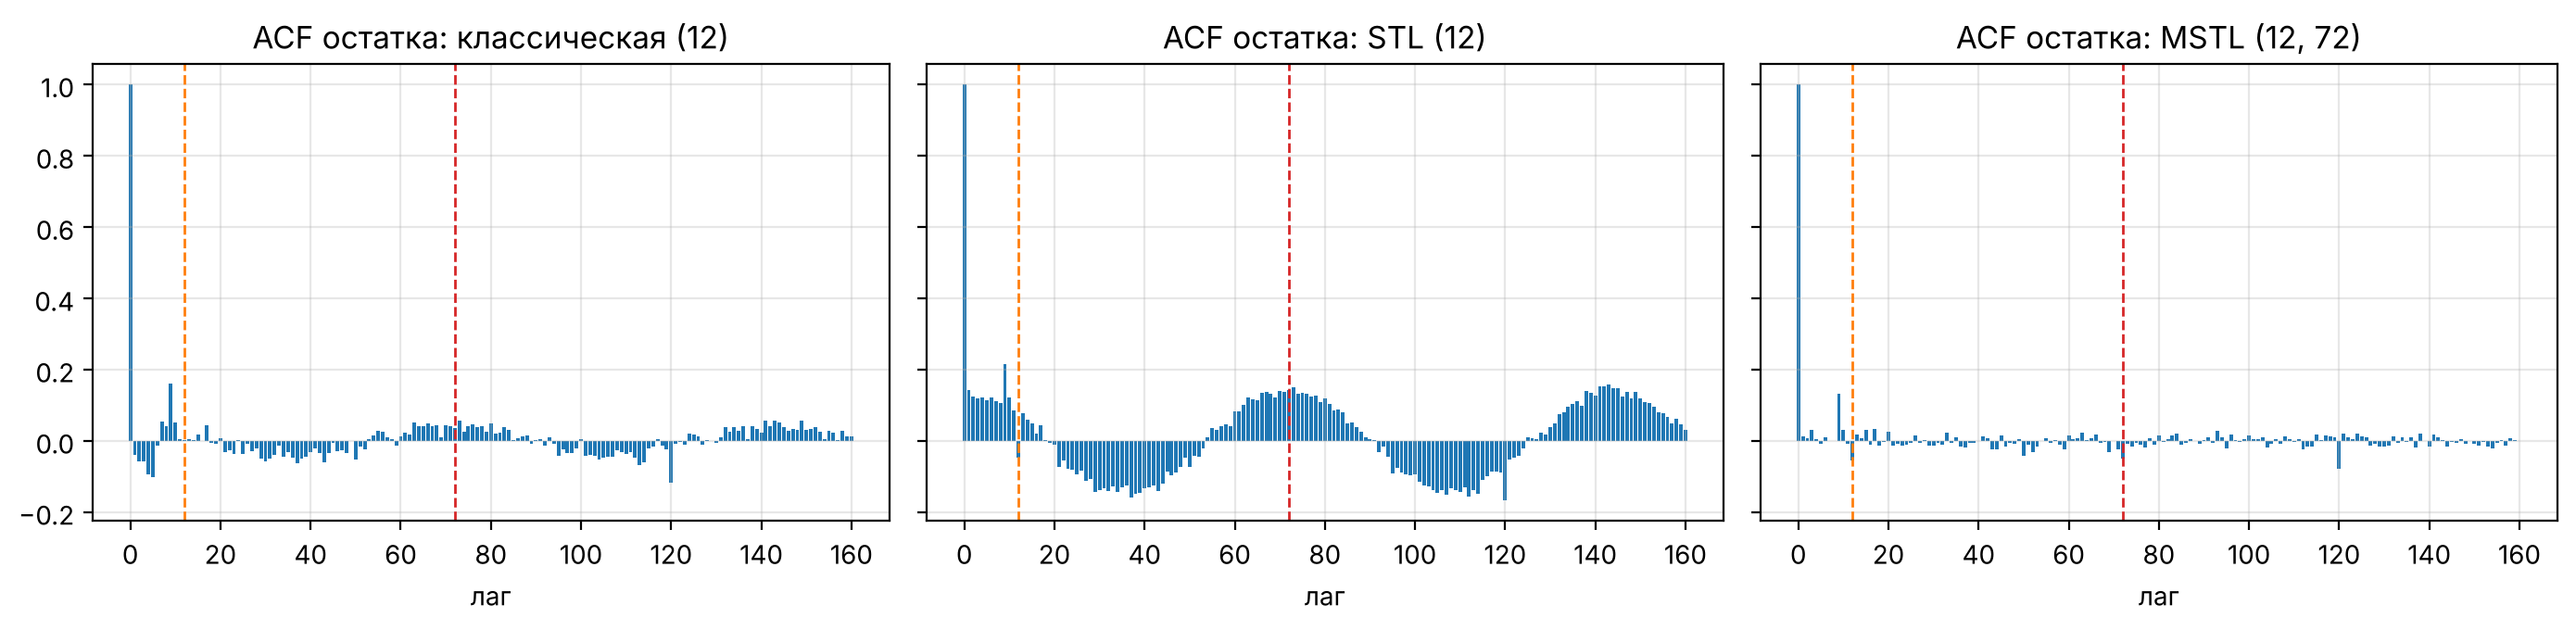

In [12]:
resids = {
    "классическая (12)": cl.resid,
    "STL (12)": stl.resid,
    "MSTL (12, 72)": mstl.resid,
}
common = cl.resid.dropna().index

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, sharey=True)
for ax, (name, r) in zip(axes, resids.items()):
    ax.plot(r.index, r, lw=0.6); ax.set_title("Остаток: " + name)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (name, r) in zip(axes, resids.items()):
    ar = acf(r.loc[common], nlags=NLAGS, fft=True)
    ax.bar(range(NLAGS + 1), ar, width=0.8)
    ax.axvline(P_SHORT, color="C1", ls="--", lw=1); ax.axvline(P_LONG, color="C3", ls="--", lw=1)
    ax.set_title("ACF остатка: " + name); ax.set_xlabel("лаг")
plt.tight_layout(); plt.show()

### 6.2 Таблица: дисперсия остатка и автокорреляция на лагах 12 и 72

* **дисперсия** — обычная дисперсия остатка (на неё влияют выбросы);
* **робастное σ** — 1.4826 · MAD, то есть «типичный» разброс без выбросов;
* **ACF(12), ACF(72)** — автокорреляция остатка на лагах короткой и длинной сезонности.

Для сравнения добавлена строка «эталон»: истинный остаток (шум σ=2 плюс выбросы).

In [13]:
def stats(r):
    r = r.loc[common]
    ar = acf(r, nlags=NLAGS, fft=True)
    mad = (r - r.median()).abs().median()
    return {"дисперсия": r.var(), "робастное σ": 1.4826 * mad, "ACF(12)": ar[P_SHORT], "ACF(72)": ar[P_LONG]}

table = {name: stats(r) for name, r in resids.items()}
table["эталон (шум + выбросы)"] = stats(true_resid)
pd.DataFrame(table).T.round(2)

,дисперсия,робастное σ,ACF(12),ACF(72)
классическая (12),9.76,2.08,0.00,0.04
STL (12),10.49,1.77,-0.05,0.14
"MSTL (12, 72)",9.30,1.45,-0.05,-0.05
эталон (шум + выбросы),10.14,1.96,-0.01,-0.01


### 6.3 Ошибка компонент относительно эталона (RMSE)

Считается на общем наборе точек. У классической декомпозиции и STL есть только одна сезонная компонента (период 12), поэтому для длинной сезонности у них прочерк.

In [14]:
def rmse(a, b):
    d = (a - b).loc[common]
    return float(np.sqrt((d ** 2).mean()))

rows = {
    "классическая (12)": {
        "тренд": rmse(cl.trend, true_trend_full),
        "сезонность 12": rmse(cl.seasonal, true_s_short),
        "сезонность 72": np.nan,
    },
    "STL (12)": {
        "тренд": rmse(stl.trend, true_trend_full),
        "сезонность 12": rmse(stl.seasonal, true_s_short),
        "сезонность 72": np.nan,
    },
    "MSTL (12, 72)": {
        "тренд": rmse(mstl.trend, true_trend_full),
        "сезонность 12": rmse(mstl.seasonal["seasonal_12"], true_s_short),
        "сезонность 72": rmse(mstl.seasonal["seasonal_72"], true_s_long),
    },
}
pd.DataFrame(rows).T.round(2)

,тренд,сезонность 12,сезонность 72
классическая (12),13.63,0.13,NaN
STL (12),12.97,1.10,NaN
"MSTL (12, 72)",0.45,0.81,0.7


## 7. Интерпретация

### 7.1 Куда делась длинная сезонность

Если у метода нет компоненты для периода 72, этот цикл должен оказаться либо в остатке, либо в тренде. Смотрим амплитуду 6-часовой волны в тренде и остатке каждого метода (оценка по фазам 6-часового цикла).

In [15]:
def cycle_amp(s):
    s = s.loc[common]
    p = pd.Series(s.to_numpy(), index=s.index).groupby(pos72[idx.get_indexer(s.index)]).median()
    return float((p.max() - p.min()) / 2)

amp_tab = pd.DataFrame({
    "в тренде": {
        "классическая (12)": cycle_amp(cl.trend - true_trend_full),
        "STL (12)": cycle_amp(stl.trend - true_trend_full),
        "MSTL (12, 72)": cycle_amp(mstl.trend - true_trend_full),
    },
    "в остатке": {
        "классическая (12)": cycle_amp(cl.resid),
        "STL (12)": cycle_amp(stl.resid),
        "MSTL (12, 72)": cycle_amp(mstl.resid),
    },
})
print("Амплитуда 6-часовой волны (истинная амплитуда: 20.0):")
amp_tab.round(1)

Амплитуда 6-часовой волны (истинная амплитуда: 20.0):


,в тренде,в остатке
классическая (12),19.1,1.6
STL (12),18.2,1.9
"MSTL (12, 72)",0.0,0.3


### 7.2 Сезонные профили: метод против эталона

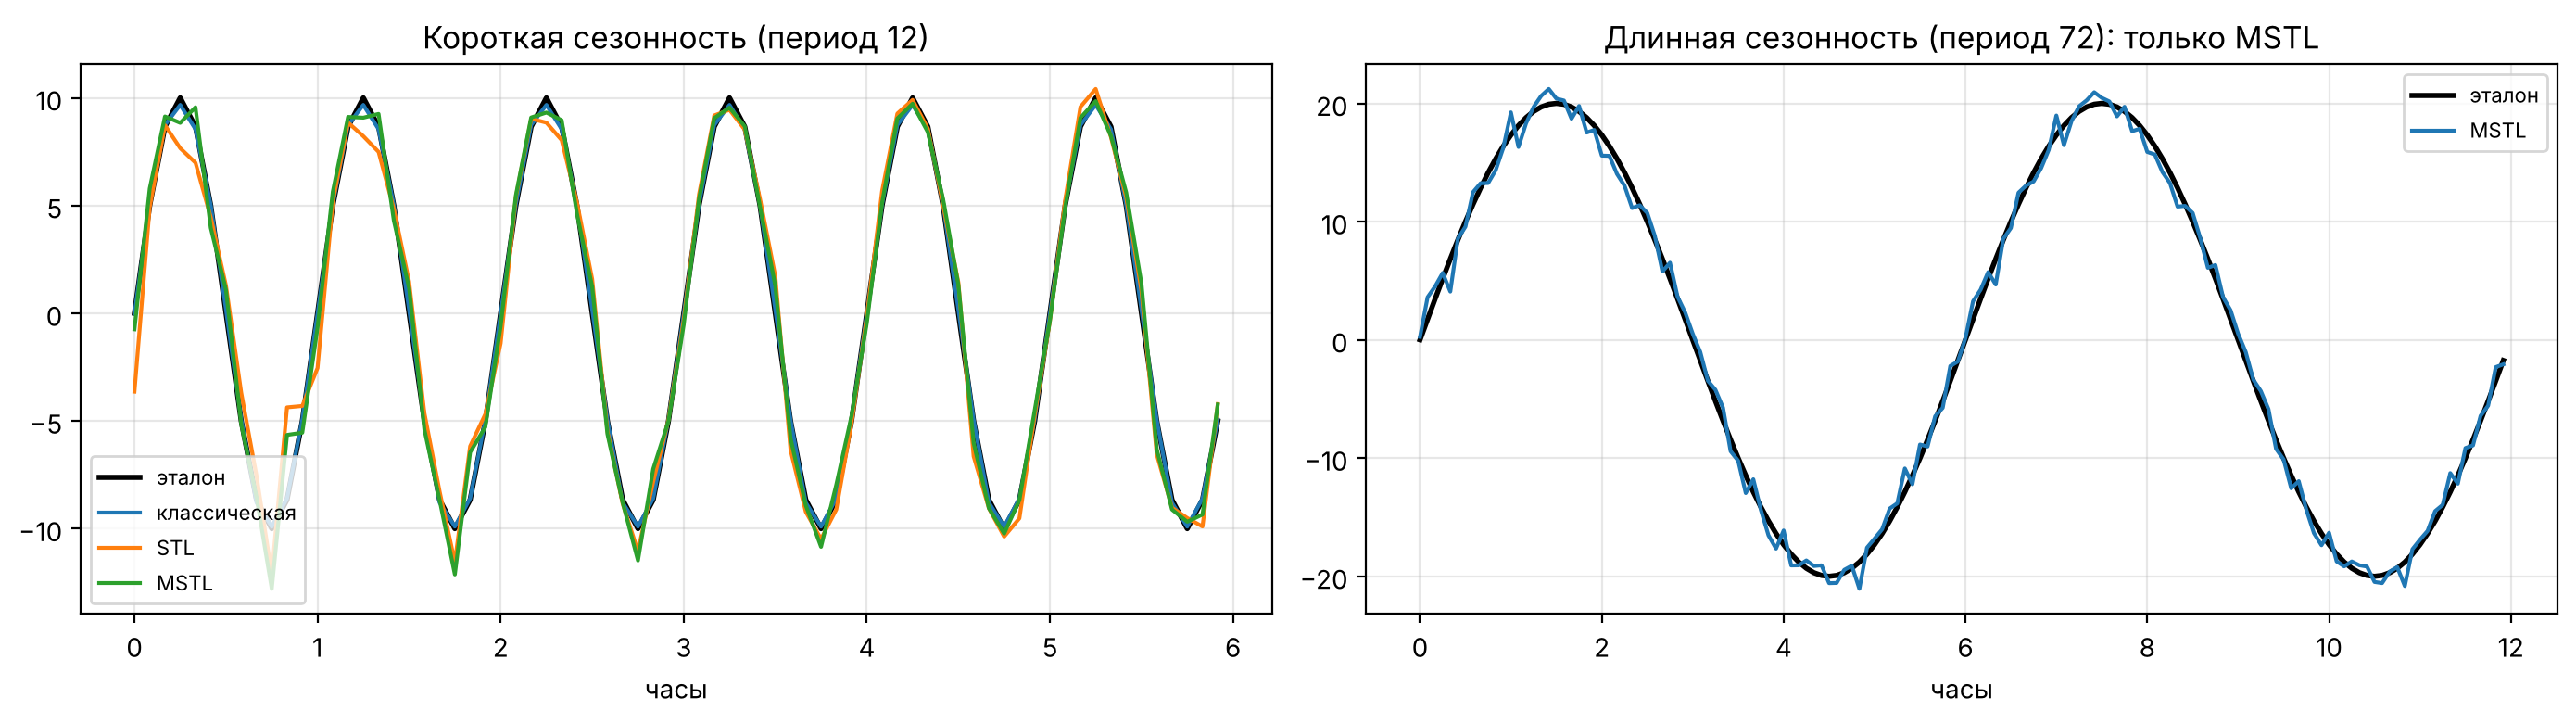

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sl = slice(0, P_LONG)   # один 6-часовой цикл
x = np.arange(P_LONG) * 5 / 60
axes[0].plot(x, true_s_short.iloc[sl], "k", lw=2, label="эталон")
axes[0].plot(x, cl.seasonal.iloc[sl], label="классическая")
axes[0].plot(x, stl.seasonal.iloc[sl], label="STL")
axes[0].plot(x, mstl.seasonal["seasonal_12"].iloc[sl], label="MSTL")
axes[0].set_title("Короткая сезонность (период 12)"); axes[0].set_xlabel("часы"); axes[0].legend(fontsize=8)

sl2 = slice(0, 2 * P_LONG)
x2 = np.arange(2 * P_LONG) * 5 / 60
axes[1].plot(x2, true_s_long.iloc[sl2], "k", lw=2, label="эталон")
axes[1].plot(x2, mstl.seasonal["seasonal_72"].iloc[sl2], label="MSTL")
axes[1].set_title("Длинная сезонность (период 72): только MSTL"); axes[1].set_xlabel("часы"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.3 Тренд после удаления сезонностей, сдвиг уровня

Серой вертикалью отмечен момент сдвига уровня (+8).

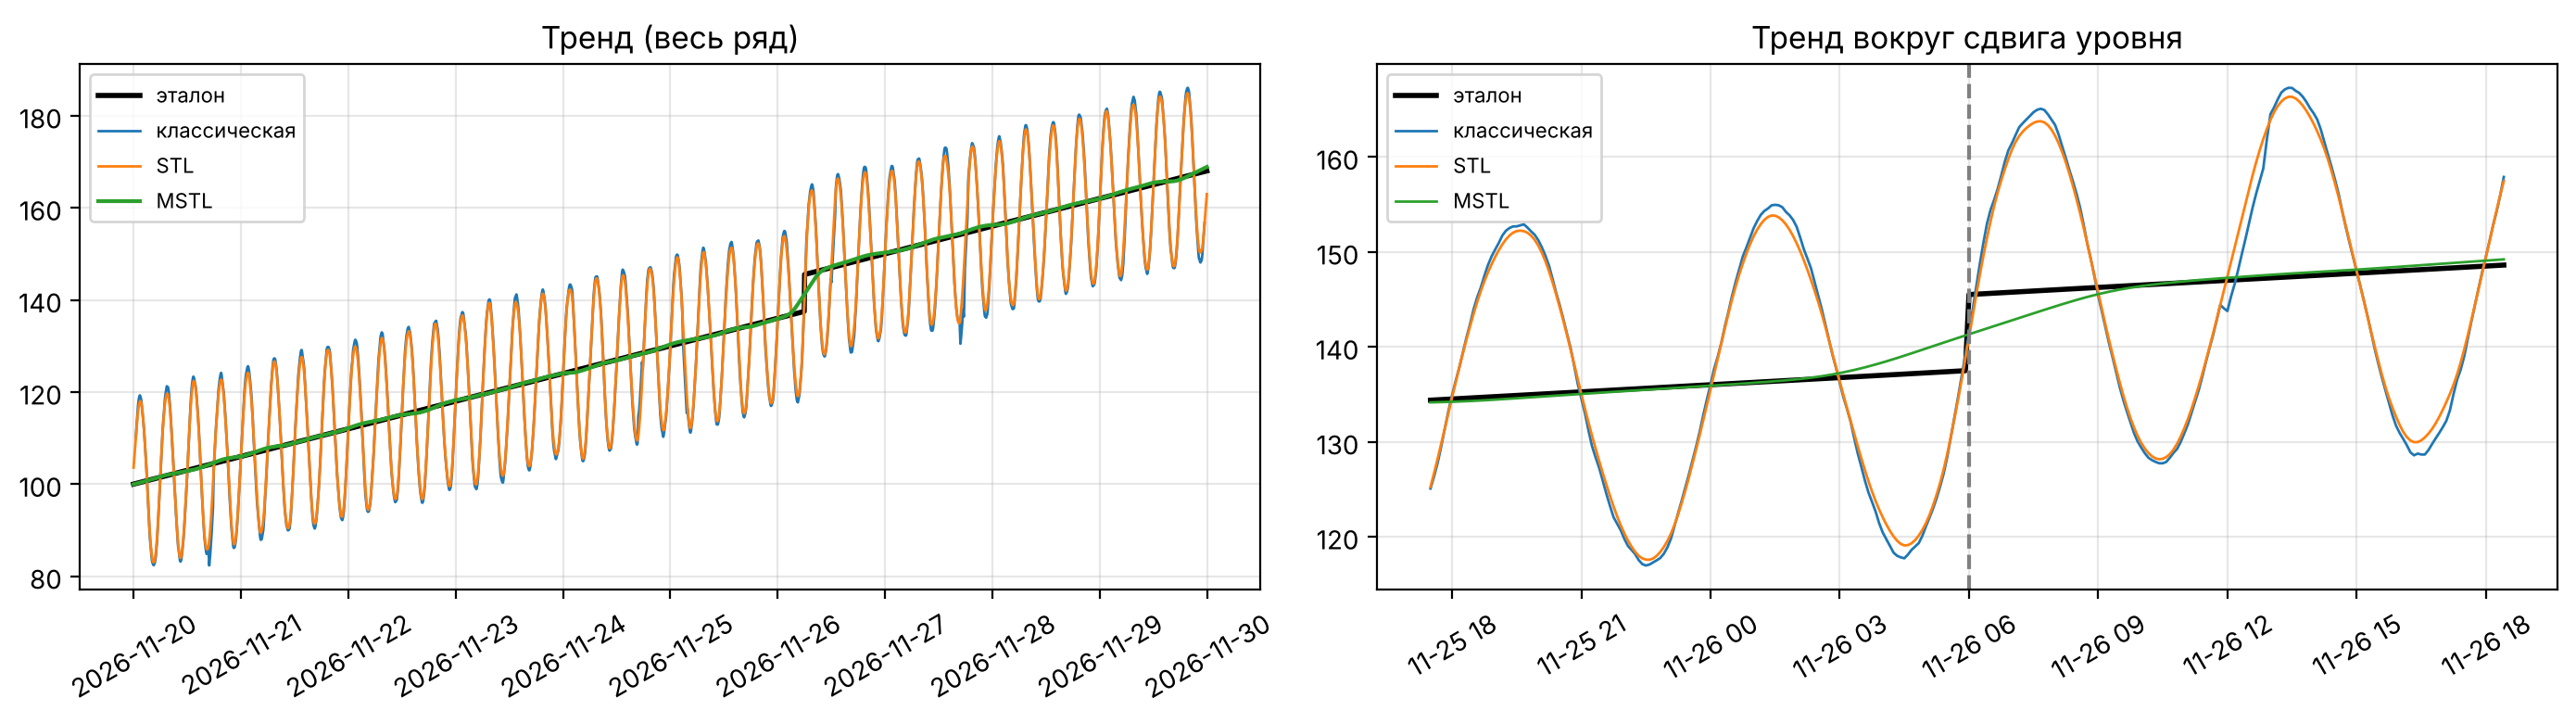

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(y.index, true_trend_full, "k", lw=2, label="эталон")
axes[0].plot(y.index, cl.trend, lw=1, label="классическая")
axes[0].plot(y.index, stl.trend, lw=1, label="STL")
axes[0].plot(y.index, mstl.trend, lw=1.5, label="MSTL")
axes[0].set_title("Тренд (весь ряд)"); axes[0].legend(fontsize=8); axes[0].tick_params(axis="x", rotation=30)

lo, hi = SHIFT_AT - 150, SHIFT_AT + 150
for name, s in [("эталон", true_trend_full), ("классическая", cl.trend), ("STL", stl.trend), ("MSTL", mstl.trend)]:
    axes[1].plot(y.index[lo:hi], s.iloc[lo:hi], lw=2 if name == "эталон" else 1, color="k" if name == "эталон" else None, label=name)
axes[1].axvline(y.index[SHIFT_AT], color="gray", ls="--")
axes[1].set_title("Тренд вокруг сдвига уровня"); axes[1].legend(fontsize=8); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 8. Выводы

**Что показали результаты (ряд: тренд + две сезонности 12 и 72 + 6 выбросов + сдвиг уровня +8)**

1. **Модель аддитивная.** Уровень ряда вырос со 102 до 166, а размах сезонности остался прежним (51.0 в первых циклах и 50.6 в последних, корреляция с уровнем 0.12).
2. **Две сезонности подтверждаются ACF.** У детрендированного ряда автокорреляция на лаге 72 равна 0.94, на лаге 12 — 0.57. Пики на этих лагах и на heatmap говорят о двух периодах.
3. **Классическая и STL с `period=12` кладут длинный цикл не в остаток, а в тренд.** Это отличается от ожидания в тексте практики («структура останется в остатке»). Причина: окно, которым оценивается тренд (13 точек у классической, 23 у STL по умолчанию), короче периода 72, поэтому 6-часовая волна проходит в тренд почти целиком: её амплитуда в тренде 19.1 и 18.2 при истинной 20. Ошибка тренда (RMSE) 13.6 у классической и 13.0 у STL, у MSTL 0.45.
4. **Дисперсия остатка здесь почти не различает методы.** Она равна 9.76 (классическая), 10.49 (STL), 9.30 (MSTL) при 10.14 у эталона и в основном определяется шестью выбросами. Главная проблема классической и STL (мусор в тренде) в остаток не попадает, поэтому проверять нужно и тренд, и остаток. Робастное σ остатка: 2.08, 1.77, 1.45 при истинных 1.96. У MSTL оно ниже истинного: метод немного «подстраивается» под шум.
5. **Остатки без структуры у всех методов, но у STL есть слабый след длинной сезонности.** ACF остатка на лаге 12 около 0 у всех. На лаге 72: 0.04 (классическая), 0.14 (STL), −0.05 (MSTL).
6. **Короткую сезонность все три метода восстанавливают хорошо** (RMSE от 0.13 до 1.10 при амплитуде 10). Длинную восстанавливает только MSTL (RMSE 0.70 при амплитуде 20). Лучшая оценка короткой сезонности у классического метода объясняется тем, что истинная сезонность строго периодична, а у него одна сезонная форма на весь ряд.
7. **Сдвиг уровня.** Классическая и STL повторяют его вместе с длинной волной, у MSTL тренд очищен от обеих сезонностей, но скачок размазан в плавный подъём шириной около нескольких часов (окно сглаживания тренда по умолчанию).
8. **Края.** Классическая декомпозиция потеряла 12 точек из 2880 (по 6 с каждого края); STL и MSTL вернули оценки для всех точек.

**Когда какой метод**

* **Классическая:** быстрый EDA, одна устойчивая сезонность, длинный ряд, где потеря краёв неважна, и как baseline.
* **STL:** одна сезонность, в данных есть выбросы (`robust=True`) или сезонная форма медленно меняется. При других сезонностях, не учтённых в `period`, нужно отдельно смотреть на тренд.
* **MSTL:** обязателен при двух и более сезонностях. Здесь он единственный дал чистый тренд (RMSE 0.45 против 13–14) и отдельную длинную сезонность.

**Ограничения и оговорки**

* Ряд синтетический, эталон известен, поэтому можно измерять ошибку компонент. В реальных данных эталона нет, и оценка идёт только по остатку, ACF и графикам.
* Параметры `season`, `trend` и `windows` оставлены по умолчанию (подбор — часть домашнего задания). Результат, особенно сглаживание сдвига уровня, зависит от них.
* Периоды 12 и 72 кратны, поэтому в MSTL сезонности возможно идентифицируются частично; оценка здесь хорошая, потому что мы знаем истинные периоды и амплитуды.
* Результаты получены на одном ряду (один `seed`); для устойчивых выводов нужны повторы на разных реализациях.
